# Control de calidad de manzanas: segmentación por instancia y estado (sana / deteriorada)


## 1. Clonar el repositorio (código, modelo y resultados)

In [2]:
import os
REPO = "/content/proyectoAprendizaje"
if not os.path.exists(REPO):
    !git clone https://github.com/EMatCM/proyectoAprendizaje.git {REPO}
%cd {REPO}
!git pull
!ls modelos resultados

/content/proyectoAprendizaje
Already up to date.
modelos:
baseline_v1.pt

resultados:
baseline_test.json


## 2. Importaciones

In [3]:
# Colab ya trae torch, torchvision y pillow. Fuera de Colab: pip install -r requirements.txt
import json, random, time, hashlib, shutil
from pathlib import Path

import torch
import torch.nn as nn
from PIL import Image
from torchvision import datasets, models, transforms

## 3. Interruptores, parámetros y rutas

In [4]:
# ---- Interruptores ----
DESCARGAR_DATASET = True   # True solo para reentrenar o evaluar en test (requiere el dataset)
SUBIR_A_GIT = False         # True para hacer commit y push de modelos/resultados/docs
LANZAR_GRADIO = False       # True para abrir la interfaz Gradio

# ---- Parámetros ----
SEMILLA = 42
TAM = 224
MEDIA, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
CLASE_MALA = "rottenapples"   # clase positiva para las métricas

# ---- Rutas ----
REPO = "/content/proyectoAprendizaje"
RUTA_DATOS = "/content/apples_dataset"                  # el dataset va fuera del repo
MODELO_PATH = Path(f"{REPO}/modelos/baseline_v1.pt")    # baseline original (v1)
MODELO_NUEVO = Path(f"{REPO}/modelos/baseline_v2.pt")   # baseline reentrenado con val (v2)

def fijar_semilla(s=SEMILLA):
    random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
fijar_semilla()
print("Dispositivo:", dev)

Dispositivo: cuda


## 4. Transformaciones, modelo y métricas

In [5]:
def tf_eval():
    return transforms.Compose([
        transforms.Resize((TAM, TAM)),
        transforms.ToTensor(),
        transforms.Normalize(MEDIA, STD),
    ])

def tf_train():
    return tf_eval()   # baseline SIN aumento de datos

def crear_modelo(n_clases=2, congelar=True):
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    if congelar:
        for p in m.parameters():
            p.requires_grad = False
    m.fc = nn.Linear(m.fc.in_features, n_clases)
    return m

In [6]:
@torch.no_grad()
def evaluar_loader(modelo, loader, clases):
    modelo.eval()
    idx_mala = clases.index(CLASE_MALA)
    tp = fp = fn = tn = 0
    for x, y in loader:
        x, y = x.to(dev), y.to(dev)
        pred = modelo(x).argmax(1)
        for p, t in zip(pred.tolist(), y.tolist()):
            if p == idx_mala and t == idx_mala: tp += 1
            elif p == idx_mala and t != idx_mala: fp += 1
            elif p != idx_mala and t == idx_mala: fn += 1
            else: tn += 1
    total = tp + fp + fn + tn
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return {"accuracy": (tp + tn) / total if total else 0.0,
            "precision_mala": prec, "recall_mala": rec, "f1_mala": f1,
            "matriz_confusion": {"TP": tp, "FP": fp, "FN": fn, "TN": tn}, "n": total}

# Parte A. Varias manzanas por foto


### A1. Parámetros de la segmentación

In [7]:
import os, time
import numpy as np
from PIL import Image, ImageDraw, ImageFont
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2, MaskRCNN_ResNet50_FPN_V2_Weights
from torchvision.transforms.functional import to_tensor

# ---- Parámetros de la segmentación ----
UMBRAL_DET = 0.5        # confianza para aceptar una manzana sin más condiciones
UMBRAL_RESCATE = 0.35   # entre este valor y UMBRAL_DET solo se acepta si NO se pega a otra manzana (rescata podridas dudosas)
UMBRAL_MASCARA = 0.5    # umbral para volver binaria la máscara suave del detector
UMBRAL_MALA = 0.5       # probabilidad mínima para decir "deteriorada"
CONF_BAJA = 0.6         # por debajo de esta confianza se avisa que el resultado es incierto
MARGEN = 0.08           # margen extra alrededor de cada recorte (8 %)
MAX_LADO = 1024         # las fotos más grandes se reducen a este lado máximo
MIN_AREA_FRAC = 0.002   # descarta detecciones menores al 0,2 % de la imagen
FRAC_CONTENIDA = 0.8    # una máscara 'contiene' a otra si cubre al menos este % del área de la otra
MAX_CONTENIDAS = 2      # una detección que contiene a 2 o más manzanas es un grupo, no una manzana
MAX_AREA_REL = 4.0      # con 6 o más manzanas seguras, una detección más grande que 4 veces la mediana es un grupo (None = desactivar)
IOU_DUPLICADA = 0.6     # dos máscaras con IoU >= esto son la misma manzana: se queda la de mayor puntaje
SOLAPE_RESCATE = 0.3    # una detección dudosa se descarta si más de este % de su área cae sobre otra ya aceptada
COLOR = {"sana": (40, 170, 60), "deteriorada": (220, 40, 40)}

### A2. Cargar clasificador y detector

In [8]:
# ---- Clasificador de estado (el nuestro) ----
# Usa baseline_v2.pt si existe en el repo; si no, baseline_v1.pt.
MODELO_CLF = MODELO_NUEVO if MODELO_NUEVO.exists() else MODELO_PATH
ck_clf = torch.load(MODELO_CLF, map_location=dev)
clases_clf = ck_clf["clases"]
clasificador = crear_modelo(len(clases_clf), congelar=False)
clasificador.load_state_dict(ck_clf["state_dict"])
clasificador = clasificador.to(dev).eval()
print("Clasificador:", MODELO_CLF.name, "| Clases:", clases_clf)

# ---- Detector / segmentador (externo: Mask R-CNN preentrenado en COCO, no se entrena) ----
pesos_det = MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT
detector = maskrcnn_resnet50_fpn_v2(weights=pesos_det).to(dev).eval()
ID_MANZANA = pesos_det.meta["categories"].index("apple")
print("Detector cargado | id de 'apple' en COCO:", ID_MANZANA)

# El detector COCO llama 'donut', 'orange' o 'cake' a muchas manzanas muy podridas (marrones y arrugadas).
# Se aceptan esas clases como "posible manzana"; 'bowl' y otras no, porque darían falsos positivos.
CLASES_FRUTA = ["apple", "orange", "donut", "cake"]
IDS_FRUTA = torch.tensor([pesos_det.meta["categories"].index(c) for c in CLASES_FRUTA], device=dev)
print("Clases aceptadas como manzana:", CLASES_FRUTA)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 169MB/s]


Clasificador: baseline_v1.pt | Clases: ['freshapples', 'rottenapples']
Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:03<00:00, 51.8MB/s]


Detector cargado | id de 'apple' en COCO: 53
Clases aceptadas como manzana: ['apple', 'orange', 'donut', 'cake']


### A3. Segmentar, recortar y clasificar

In [9]:
def filtrar_instancias(puntajes, mascaras, umbral_det):
    """Índices (por puntaje decreciente) de las detecciones que son UNA manzana.

    Trabaja con las máscaras, no con las cajas: una caja grande puede tocar muchas manzanas sin ser un grupo.
    1) quita grupos: máscaras que contienen a 2 o más manzanas seguras, o que son enormes frente a las demás;
    2) quita duplicados: de dos máscaras casi iguales deja la de mayor puntaje;
    3) las de puntaje dudoso (entre UMBRAL_RESCATE y umbral_det) solo se aceptan si no se montan sobre otra.
    """
    n = len(puntajes)
    if n == 0:
        return np.zeros(0, dtype=int)
    M = np.asarray(mascaras).reshape(n, -1).astype(np.float32)
    area = M.sum(1)
    inter = M @ M.T                                   # píxeles en común entre cada par de máscaras
    seguras = np.asarray(puntajes) >= umbral_det
    vivos = np.ones(n, dtype=bool)
    mediana = np.median(area[seguras]) if seguras.sum() >= 6 else None
    for i in range(n):
        dentro = sum(1 for j in range(n)
                     if j != i and seguras[j] and area[j] < 0.6 * area[i] and inter[i, j] >= FRAC_CONTENIDA * area[j])
        enorme = MAX_AREA_REL is not None and mediana is not None and area[i] > MAX_AREA_REL * mediana
        if dentro >= MAX_CONTENIDAS or enorme:
            vivos[i] = False
    kept = []
    for i in np.argsort(-np.asarray(puntajes), kind="stable"):
        if not vivos[i]:
            continue
        if kept:
            k = np.array(kept)
            iou = inter[i, k] / (area[i] + area[k] - inter[i, k])
            if (iou >= IOU_DUPLICADA).any():
                continue
            if puntajes[i] < umbral_det and (inter[i, k] / area[i] > SOLAPE_RESCATE).any():
                continue
        kept.append(int(i))
    return np.array(kept, dtype=int)


@torch.no_grad()
def segmentar(img, umbral_det=None):
    """Devuelve cajas, puntajes y máscaras booleanas de cada manzana detectada."""
    umbral_det = UMBRAL_DET if umbral_det is None else umbral_det
    piso = min(UMBRAL_RESCATE, umbral_det)            # el detector entrega también las dudosas; luego se filtran
    out = detector([to_tensor(img).to(dev)])[0]
    ok = torch.isin(out["labels"], IDS_FRUTA) & (out["scores"] >= piso)
    cajas = out["boxes"][ok].cpu().numpy()
    puntajes = out["scores"][ok].cpu().numpy()
    mascaras = (out["masks"][ok, 0] > UMBRAL_MASCARA).cpu().numpy()
    area_min = MIN_AREA_FRAC * img.width * img.height
    keep = np.array([i for i, m in enumerate(mascaras) if m.sum() >= area_min], dtype=int)
    cajas, puntajes, mascaras = cajas[keep], puntajes[keep], mascaras[keep]
    keep = filtrar_instancias(puntajes, mascaras, umbral_det)
    return cajas[keep], puntajes[keep], mascaras[keep]


def recortar(arr, caja, mascara, margen=MARGEN):
    """Recorta una manzana y pone fondo blanco fuera de su máscara."""
    x1, y1, x2, y2 = caja
    mx, my = margen * (x2 - x1), margen * (y2 - y1)
    x1, y1 = max(0, int(x1 - mx)), max(0, int(y1 - my))
    x2, y2 = min(arr.shape[1], int(x2 + mx)), min(arr.shape[0], int(y2 + my))
    sub = arr[y1:y2, x1:x2].copy()
    sub[~mascara[y1:y2, x1:x2]] = 255
    return Image.fromarray(sub)


@torch.no_grad()
def prob_deteriorada(recortes, lote=32):
    """Probabilidad de 'deteriorada' para cada recorte (el mismo clasificador del baseline)."""
    if not recortes:
        return []
    idx = clases_clf.index(CLASE_MALA)
    probs = []
    for i in range(0, len(recortes), lote):
        x = torch.stack([tf_eval()(r) for r in recortes[i:i + lote]]).to(dev)
        probs += torch.softmax(clasificador(x), dim=1)[:, idx].cpu().tolist()
    return probs

### A4. Análisis de una imagen y resumen

In [10]:
def analizar(img, umbral_mala=None, umbral_det=None):
    """Segmenta, clasifica cada manzana y arma el resumen de la imagen."""
    umbral_mala = UMBRAL_MALA if umbral_mala is None else umbral_mala
    t0 = time.time()
    img = img.convert("RGB")
    factor = 1.0
    if max(img.size) > MAX_LADO:                      # fotos de celular muy grandes
        factor = MAX_LADO / max(img.size)
        img = img.resize((round(img.width * factor), round(img.height * factor)))

    cajas, puntajes, mascaras = segmentar(img, umbral_det)
    arr = np.asarray(img)
    recortes = [recortar(arr, c, m) for c, m in zip(cajas, mascaras)]
    probs = prob_deteriorada(recortes)

    instancias = []
    for i, (c, s, m, p) in enumerate(zip(cajas, puntajes, mascaras, probs), 1):
        mala = p >= umbral_mala
        instancias.append({
            "id": i,
            "caja": [float(v) for v in c],
            "puntaje_det": float(s),
            "prob_deteriorada": float(p),
            "estado": "deteriorada" if mala else "sana",
            "confianza": float(p if mala else 1 - p),
            "area": int(m.sum()),
            "mascara": m,
        })

    n_malas = sum(d["estado"] == "deteriorada" for d in instancias)
    avisos = []
    if not instancias:
        avisos.append("No se detectó ninguna manzana. Prueba bajar el umbral de detección.")
    dudosas = [d["id"] for d in instancias if d["confianza"] < CONF_BAJA]
    if dudosas:
        avisos.append(f"Confianza baja en las manzanas {dudosas}: revisar a mano.")
    return {"imagen": img, "factor": factor, "instancias": instancias,
            "total": len(instancias), "sanas": len(instancias) - n_malas,
            "deterioradas": n_malas, "avisos": avisos, "segundos": time.time() - t0}


def resumen_texto(res):
    lineas = [f"Manzanas: {res['total']} | sanas: {res['sanas']} | deterioradas: {res['deterioradas']} "
              f"| {res['segundos']:.1f} s"]
    for d in res["instancias"]:
        lineas.append(f"  #{d['id']}: {d['estado']} (confianza {d['confianza']:.0%}, "
                      f"detección {d['puntaje_det']:.0%})")
    lineas += [f"Aviso: {a}" for a in res["avisos"]]
    return "\n".join(lineas)

### A5. Dibujar el resultado

In [11]:
def _borde(m, grosor=3):
    """Contorno de una máscara booleana, sin necesidad de OpenCV."""
    interior = m.copy()
    for _ in range(grosor):
        p = np.pad(interior, 1, constant_values=False)
        interior = p[1:-1, 1:-1] & p[:-2, 1:-1] & p[2:, 1:-1] & p[1:-1, :-2] & p[1:-1, 2:]
    return m & ~interior


def _fuente(tam):
    for ruta in ["/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf", "DejaVuSans-Bold.ttf"]:
        try:
            return ImageFont.truetype(ruta, tam)
        except OSError:
            pass
    return ImageFont.load_default()


def dibujar(res, alpha=0.40):
    """Pinta cada manzana (verde = sana, rojo = deteriorada) con contorno y etiqueta."""
    arr = np.asarray(res["imagen"]).astype(np.float32)
    for d in res["instancias"]:
        color = COLOR[d["estado"]]
        m = d["mascara"]
        arr[m] = (1 - alpha) * arr[m] + alpha * np.array(color, dtype=np.float32)
        arr[_borde(m)] = color
    out = Image.fromarray(arr.clip(0, 255).astype(np.uint8))
    dr = ImageDraw.Draw(out)
    fuente = _fuente(max(14, out.width // 45))
    for d in res["instancias"]:
        color = COLOR[d["estado"]]
        texto = f"#{d['id']} {d['estado']} {d['confianza']:.0%}"
        x1, y1 = d["caja"][:2]
        bb = dr.textbbox((0, 0), texto, font=fuente)
        w, h = bb[2] - bb[0], bb[3] - bb[1]
        px, py = x1, max(0, y1 - h - 10)
        dr.rectangle([px, py, px + w + 10, py + h + 10], fill=color)
        dr.text((px + 5, py + 3), texto, fill="white", font=fuente)
    return out

### A6. Probar con una foto de varias manzanas

Saving images (16).jpg to images (16).jpg
Manzanas: 9 | sanas: 0 | deterioradas: 9 | 0.3 s
  #1: deteriorada (confianza 100%, detección 97%)
  #2: deteriorada (confianza 86%, detección 96%)
  #3: deteriorada (confianza 96%, detección 96%)
  #4: deteriorada (confianza 98%, detección 92%)
  #5: deteriorada (confianza 100%, detección 92%)
  #6: deteriorada (confianza 69%, detección 91%)
  #7: deteriorada (confianza 92%, detección 91%)
  #8: deteriorada (confianza 94%, detección 76%)
  #9: deteriorada (confianza 97%, detección 59%)


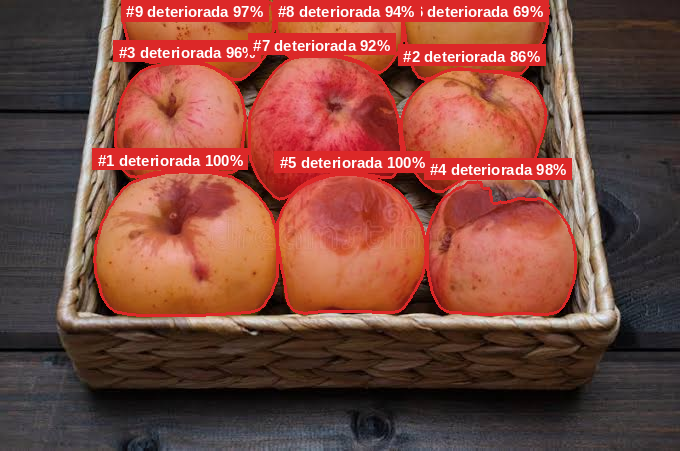

In [71]:
from google.colab import files
from IPython.display import display

subida = files.upload()          # sube una foto con varias manzanas
if not subida:
    print("No se subió ninguna imagen. Vuelve a ejecutar esta celda y elige un archivo.")
else:
    ruta = list(subida.keys())[0]
    res = analizar(Image.open(ruta))
    print(resumen_texto(res))
    display(dibujar(res))
    os.remove(ruta)              # para que la foto no quede dentro del repositorio

Saving Captura de pantalla 2026-11-20 204151.png to Captura de pantalla 2026-11-20 204151.png
Captura de pantalla 2026-11-20 204151.png | baseline_v2: 10 sanas / 4 deterioradas
Captura de pantalla 2026-11-20 204151.png | exp9_recortes_color_ext_rojas: 7 sanas / 7 deterioradas


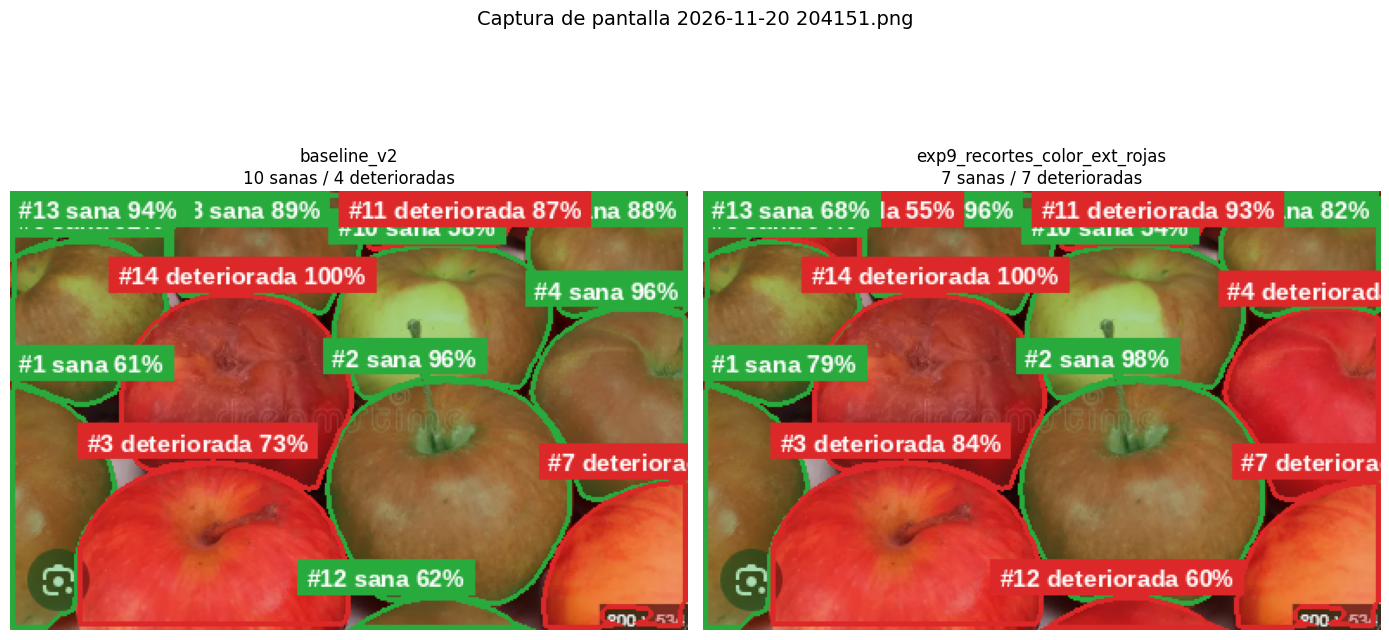

In [95]:
import io
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from google.colab import files

MODELOS_COMP = ["baseline_v2", "exp9_recortes_color_ext_rojas"]
SALIDA = Path("/content/comparaciones"); SALIDA.mkdir(exist_ok=True)

subidas = files.upload()          # elige una o varias fotos
for nombre_arch, datos in subidas.items():
    img = Image.open(io.BytesIO(datos)).convert("RGB")
    fig, ejes = plt.subplots(1, len(MODELOS_COMP), figsize=(7 * len(MODELOS_COMP), 8))
    for ax, nombre in zip(ejes, MODELOS_COMP):
        cargar_clasificador(nombre)
        res = analizar(img)
        print(f"{nombre_arch} | {nombre}: {res['sanas']} sanas / {res['deterioradas']} deterioradas")
        ax.imshow(dibujar(res))
        ax.set_title(f"{nombre}\n{res['sanas']} sanas / {res['deterioradas']} deterioradas", fontsize=12)
        ax.axis("off")
    fig.suptitle(nombre_arch, fontsize=14)
    plt.tight_layout()
    fig.savefig(SALIDA / f"{Path(nombre_arch).stem}_comparacion.png", dpi=110)
    plt.show()

cargar_clasificador("exp9_recortes_color_ext_rojas")   # deja exp9 activo

### A7. Evaluación por manzana (con tus fotos anotadas)



In [13]:
import json
from pathlib import Path

# Nombre de la categoría en tu exportación COCO -> estado. Ajústalo a como llamaste tus clases.
ESTADO_POR_CATEGORIA = {"sana": "sana", "deteriorada": "deteriorada"}


def cargar_coco(ruta_json):
    """Lee anotaciones COCO con polígonos. Devuelve {archivo: [{poligonos, estado}]}."""
    coco = json.load(open(ruta_json, encoding="utf-8"))
    cats = {c["id"]: c["name"] for c in coco["categories"]}
    nombres = {i["id"]: i["file_name"] for i in coco["images"]}
    gt = {i["file_name"]: [] for i in coco["images"]}
    omitidas = 0
    for a in coco["annotations"]:
        seg = a.get("segmentation")
        cat = cats.get(a["category_id"])
        if not isinstance(seg, list) or not seg or cat not in ESTADO_POR_CATEGORIA:
            omitidas += 1               # RLE, vacías o de otra categoría
            continue
        gt[nombres[a["image_id"]]].append({"poligonos": seg, "estado": ESTADO_POR_CATEGORIA[cat]})
    if omitidas:
        print(f"Aviso: {omitidas} anotaciones omitidas (sin polígono o categoría desconocida).")
    return gt


def rasterizar(poligonos, ancho, alto, factor):
    """Polígonos COCO -> máscara booleana, a la misma escala que la imagen analizada."""
    im = Image.new("L", (ancho, alto), 0)
    d = ImageDraw.Draw(im)
    for poly in poligonos:
        pts = [(poly[i] * factor, poly[i + 1] * factor) for i in range(0, len(poly) - 1, 2)]
        if len(pts) >= 3:
            d.polygon(pts, fill=1)
    return np.array(im, dtype=bool)


def iou(a, b):
    union = (a | b).sum()
    return float((a & b).sum() / union) if union else 0.0


def emparejar(preds, gts, iou_min=0.5):
    """Empareja predicciones con anotaciones reales, de mayor a menor IoU (uno a uno)."""
    cand = sorted(((iou(p["mascara"], g["mascara"]), i, j)
                   for i, p in enumerate(preds) for j, g in enumerate(gts)), reverse=True)
    pares, usados_p, usados_g = [], set(), set()
    for v, i, j in cand:
        if v < iou_min:
            break
        if i in usados_p or j in usados_g:
            continue
        pares.append((i, j, v))
        usados_p.add(i)
        usados_g.add(j)
    return pares, usados_p, usados_g


def _div(a, b):
    return a / b if b else 0.0


def evaluar_coco(ruta_json, carpeta_imgs, iou_min=0.5, umbral_mala=None, guardar=None):
    """Evalúa por manzana: detección, IoU, conteo y estado, contra tus anotaciones reales."""
    gt = cargar_coco(ruta_json)
    det_tp = det_fp = det_fn = 0
    ious, err_total, err_malas, filas = [], [], [], []
    conf = {"TP": 0, "FP": 0, "FN": 0, "TN": 0}      # estado, solo en manzanas emparejadas
    malas_reales = malas_ok_extremo = 0
    for archivo, anots in gt.items():
        res = analizar(Image.open(Path(carpeta_imgs) / Path(archivo).name), umbral_mala)
        w, h = res["imagen"].size
        gts = [{"mascara": rasterizar(a["poligonos"], w, h, res["factor"]), "estado": a["estado"]}
               for a in anots]
        pares, up, ug = emparejar(res["instancias"], gts, iou_min)
        det_tp += len(pares)
        det_fp += len(res["instancias"]) - len(up)
        det_fn += len(gts) - len(ug)
        errores_estado = 0
        for i, j, v in pares:
            ious.append(v)
            pred, real = res["instancias"][i]["estado"], gts[j]["estado"]
            if real == "deteriorada":
                malas_reales += 1
            if pred == "deteriorada" and real == "deteriorada":
                conf["TP"] += 1; malas_ok_extremo += 1
            elif pred == "deteriorada":
                conf["FP"] += 1; errores_estado += 1
            elif real == "deteriorada":
                conf["FN"] += 1; errores_estado += 1
            else:
                conf["TN"] += 1
        malas_reales += sum(1 for j, g in enumerate(gts) if j not in ug and g["estado"] == "deteriorada")
        real_malas = sum(g["estado"] == "deteriorada" for g in gts)
        err_total.append(abs(res["total"] - len(gts)))
        err_malas.append(abs(res["deterioradas"] - real_malas))
        filas.append({"imagen": archivo, "reales": len(gts), "predichas": res["total"],
                      "no_detectadas": len(gts) - len(ug), "de_mas": len(res["instancias"]) - len(up),
                      "errores_de_estado": errores_estado,
                      "malas_reales": real_malas, "malas_predichas": res["deterioradas"]})

    prec_e, rec_e = _div(conf["TP"], conf["TP"] + conf["FP"]), _div(conf["TP"], conf["TP"] + conf["FN"])
    metricas = {
        "n_imagenes": len(gt), "n_manzanas_reales": det_tp + det_fn, "iou_minimo": iou_min,
        "deteccion": {"TP": det_tp, "FP": det_fp, "FN": det_fn,
                      "precision": _div(det_tp, det_tp + det_fp), "recall": _div(det_tp, det_tp + det_fn),
                      "iou_medio": _div(sum(ious), len(ious))},
        "conteo": {"error_abs_medio_total": _div(sum(err_total), len(err_total)),
                   "error_abs_medio_deterioradas": _div(sum(err_malas), len(err_malas)),
                   "imagenes_con_conteo_exacto": sum(e == 0 for e in err_total)},
        "estado_en_emparejadas": {**conf, "precision_deteriorada": prec_e, "recall_deteriorada": rec_e,
                                  "f1_deteriorada": _div(2 * prec_e * rec_e, prec_e + rec_e)},
        "recall_deteriorada_extremo_a_extremo": _div(malas_ok_extremo, malas_reales),
        "por_imagen": filas,
    }
    if guardar:
        Path(guardar).parent.mkdir(parents=True, exist_ok=True)
        Path(guardar).write_text(json.dumps(metricas, indent=2, ensure_ascii=False))
        print("Resultados guardados en", guardar)
    return metricas

In [14]:
# Ejecuta la evaluación cuando ya tengas tus fotos y el JSON COCO en estas rutas
RUTA_FOTOS_PROPIAS = "/content/mis_fotos"
RUTA_COCO = f"{RUTA_FOTOS_PROPIAS}/_annotations.coco.json"

if os.path.exists(RUTA_COCO):
    met = evaluar_coco(RUTA_COCO, RUTA_FOTOS_PROPIAS,
                       guardar=f"{REPO}/resultados/evaluacion_segmentacion.json")
    print(json.dumps({k: v for k, v in met.items() if k != "por_imagen"}, indent=2, ensure_ascii=False))
else:
    print("Aún no hay fotos anotadas en", RUTA_FOTOS_PROPIAS, "- evaluación omitida.")


Aún no hay fotos anotadas en /content/mis_fotos - evaluación omitida.


# Parte B. Reentrenar el baseline y medir en `test` (requiere el dataset)


### B1. Descargar el dataset

In [16]:
if DESCARGAR_DATASET:
    if not os.path.exists(RUTA_DATOS):
        if not os.path.exists("/content/apples_dataset.zip"):
            !pip install -q gdown
            !gdown 1wNny4KKgdkzarUb7xgyJZE_UjIyNmtxY -O /content/apples_dataset.zip
        !unzip -tq /content/apples_dataset.zip
        !unzip -q /content/apples_dataset.zip -d {RUTA_DATOS}
    # Si el zip traía una carpeta raíz, ajusta la ruta
    if (Path(RUTA_DATOS) / "apples_dataset" / "train").exists():
        RUTA_DATOS = str(Path(RUTA_DATOS) / "apples_dataset")
    print("RUTA_DATOS =", RUTA_DATOS)
    for split in ["train", "test"]:
        for c in sorted(p.name for p in (Path(RUTA_DATOS) / split).iterdir() if p.is_dir()):
            print(f"{split}/{c}: {len(list((Path(RUTA_DATOS) / split / c).glob('*')))}")
else:
    print("Dataset omitido (DESCARGAR_DATASET = False).")

Downloading...
From (original): https://drive.google.com/uc?id=1wNny4KKgdkzarUb7xgyJZE_UjIyNmtxY
From (redirected): https://drive.google.com/uc?id=1wNny4KKgdkzarUb7xgyJZE_UjIyNmtxY&confirm=t&uuid=d8517a79-fb61-4ee4-bd50-e824aebef772
To: /content/apples_dataset.zip
100% 669M/669M [00:08<00:00, 83.5MB/s]
No errors detected in compressed data of /content/apples_dataset.zip.
RUTA_DATOS = /content/apples_dataset
train/freshapples: 1693
train/rottenapples: 2342
test/freshapples: 395
test/rottenapples: 601


### B2. Revisar duplicados y crear `val` a partir de `train`

In [17]:
assert DESCARGAR_DATASET, "Activa DESCARGAR_DATASET = True, vuelve a ejecutar la sección 3 y la celda B1."

EXT = {".jpg", ".jpeg", ".png"}
def hashes(split):
    return {hashlib.md5(p.read_bytes()).hexdigest(): p
            for p in (Path(RUTA_DATOS) / split).rglob("*") if p.suffix.lower() in EXT}

h_tr, h_te = hashes("train"), hashes("test")
dup = set(h_tr) & set(h_te)
print(f"Duplicados exactos train <-> test: {len(dup)}")
if dup:
    print("Revisa y elimina estos duplicados antes de continuar:", [str(h_te[h]) for h in list(dup)[:5]])
# Ojo: esto solo detecta copias idénticas. Versiones rotadas o aumentadas de una misma foto
# no se detectan por hash; revisa los nombres de archivo y documenta lo que encuentres.

val_dir = Path(RUTA_DATOS) / "val"
if not val_dir.exists():
    random.seed(SEMILLA)
    for c in sorted(p.name for p in (Path(RUTA_DATOS) / "train").iterdir() if p.is_dir()):
        origen = sorted((Path(RUTA_DATOS) / "train" / c).glob("*"))
        random.shuffle(origen)
        n_val = int(0.15 * len(origen))
        (val_dir / c).mkdir(parents=True, exist_ok=True)
        for p in origen[:n_val]:
            shutil.move(str(p), val_dir / c / p.name)
        print(f"{c}: {n_val} imágenes movidas a val")
else:
    print("val ya existe, no se vuelve a crear.")

Duplicados exactos train <-> test: 0
freshapples: 253 imágenes movidas a val
rottenapples: 351 imágenes movidas a val


### B3. Función de entrenamiento (la misma para el baseline y para el experimento)

In [18]:
def entrenar(nombre, tf, epocas=5, batch=32, lr=1e-3, extra_train=None, ruta_datos=None, semilla=None):
    """Entrena solo la capa final y guarda el mejor modelo según el F1 de 'deteriorada' en val.
    extra_train: carpeta opcional (formato ImageFolder) que se suma al train, p. ej. fotos de otra fuente.
    ruta_datos: carpeta con train/ y val/ (por defecto RUTA_DATOS). semilla: por defecto SEMILLA."""
    assert DESCARGAR_DATASET, "Activa DESCARGAR_DATASET = True, vuelve a ejecutar la sección 3 y la celda B1."
    if dev.type == "cpu":
        print("Aviso: sin GPU el entrenamiento tarda unos 40 minutos. Entorno de ejecución > Cambiar tipo > T4 GPU.")
    fijar_semilla(SEMILLA if semilla is None else semilla)
    ruta = str(ruta_datos or RUTA_DATOS)
    ds_tr = datasets.ImageFolder(f"{ruta}/train", tf)
    ds_va = datasets.ImageFolder(f"{ruta}/val", tf_eval())      # validación, NO test
    cl = ds_tr.classes
    assert CLASE_MALA in cl, f"Clases encontradas: {cl}"
    n_base = len(ds_tr)
    if extra_train is not None:
        ds_ex = datasets.ImageFolder(str(extra_train), tf)
        assert set(ds_ex.classes) <= set(cl), f"Clases extra {ds_ex.classes} no válidas; esperadas {cl}"
        # la carpeta extra puede traer una sola clase: se alinean sus índices con los de train
        ds_ex.samples = [(p, ds_tr.class_to_idx[ds_ex.classes[t]]) for p, t in ds_ex.samples]
        ds_ex.targets = [t for _, t in ds_ex.samples]
        ds_tr = torch.utils.data.ConcatDataset([ds_tr, ds_ex])

    print(f"[{nombre}] clases={cl} | train={len(ds_tr)} (base {n_base} + extra {len(ds_tr) - n_base}) val={len(ds_va)}")
    dl_tr = torch.utils.data.DataLoader(ds_tr, batch_size=batch, shuffle=True, num_workers=2)
    dl_va = torch.utils.data.DataLoader(ds_va, batch_size=batch, num_workers=2)

    m_ent = crear_modelo(len(cl)).to(dev)
    opt = torch.optim.Adam(m_ent.fc.parameters(), lr=lr)
    perdida = nn.CrossEntropyLoss()

    ruta_modelo = Path(f"{REPO}/modelos/{nombre}.pt")
    ruta_modelo.parent.mkdir(parents=True, exist_ok=True)
    historial, mejor_f1, t0 = [], -1.0, time.time()
    for ep in range(1, epocas + 1):
        m_ent.train()
        total_loss = 0.0
        for x, y in dl_tr:
            x, y = x.to(dev), y.to(dev)
            opt.zero_grad()
            loss = perdida(m_ent(x), y)
            loss.backward()
            opt.step()
            total_loss += loss.item() * x.size(0)
        m = evaluar_loader(m_ent, dl_va, cl)
        historial.append({"epoca": ep, "loss": total_loss / len(ds_tr), **m})
        print(f"[{nombre}] época {ep}/{epocas} | loss={total_loss/len(ds_tr):.4f} | "
              f"val F1={m['f1_mala']:.3f} recall={m['recall_mala']:.3f} precisión={m['precision_mala']:.3f}")
        if m["f1_mala"] >= mejor_f1:      # se elige con val, nunca con test
            mejor_f1 = m["f1_mala"]
            torch.save({"state_dict": m_ent.state_dict(), "clases": cl,
                        "epoca": ep, "lr": lr, "batch": batch}, ruta_modelo)

    salida = Path(f"{REPO}/resultados/{nombre}_val.json")
    salida.parent.mkdir(parents=True, exist_ok=True)
    salida.write_text(json.dumps(historial, indent=2, ensure_ascii=False))
    print(f"Listo en {time.time()-t0:.0f}s | modelo: {ruta_modelo.name} | historial: {salida.name}")
    return historial

In [19]:
def entrenar_si_falta(nombre, *args, **kwargs):
    """Entrena solo si ese modelo todavía no existe: así se puede volver a ejecutar el notebook sin repetir.
    Si quieres reentrenarlo (por ejemplo, tras cambiar los datos), borra modelos/<nombre>.pt primero."""
    modelo = Path(f"{REPO}/modelos/{nombre}.pt")
    if modelo.exists():
        print(f"[{nombre}] ya existe en modelos/: no se reentrena. Bórralo si quieres entrenarlo de nuevo.")
        hist = Path(f"{REPO}/resultados/{nombre}_val.json")
        return json.loads(hist.read_text()) if hist.exists() else []
    return entrenar(nombre, *args, **kwargs)

### B4. Entrenar el baseline v2 (sin aumento de datos)

In [20]:
if MODELO_NUEVO.exists():
    print(f"{MODELO_NUEVO.name} ya existe: no se reentrena (es la referencia). Bórralo de modelos/ si quieres entrenarlo de nuevo.")
else:
    h_base = entrenar(MODELO_NUEVO.stem, tf_train())

[baseline_v2] clases=['freshapples', 'rottenapples'] | train=3431 (base 3431 + extra 0) val=604
[baseline_v2] época 1/5 | loss=0.2375 | val F1=0.971 recall=0.957 precisión=0.985
[baseline_v2] época 2/5 | loss=0.1098 | val F1=0.987 recall=0.989 precisión=0.986
[baseline_v2] época 3/5 | loss=0.0905 | val F1=0.980 recall=0.974 precisión=0.986
[baseline_v2] época 4/5 | loss=0.0825 | val F1=0.985 recall=0.997 precisión=0.972
[baseline_v2] época 5/5 | loss=0.0839 | val F1=0.992 recall=0.997 precisión=0.986
Listo en 116s | modelo: baseline_v2.pt | historial: baseline_v2_val.json


### B5. Evaluar en `test` (una sola vez)

Ejecuta esta celda **solo cuando ya hayas decidido qué modelo reportar usando `val`**. Si la repites para comparar modelos y elegir, estás decidiendo con `test`.

In [21]:
assert DESCARGAR_DATASET, "Activa DESCARGAR_DATASET = True, vuelve a ejecutar la sección 3 y la celda B1."

MODELO_EVALUAR = MODELO_NUEVO if MODELO_NUEVO.exists() else MODELO_PATH   # cambia aquí para evaluar otro
ck_te = torch.load(MODELO_EVALUAR, map_location=dev)
m_te = crear_modelo(len(ck_te["clases"]), congelar=False)
m_te.load_state_dict(ck_te["state_dict"])
m_te = m_te.to(dev).eval()

ds_te = datasets.ImageFolder(f"{RUTA_DATOS}/test", tf_eval())
dl_te = torch.utils.data.DataLoader(ds_te, batch_size=32, num_workers=2)
res_te = evaluar_loader(m_te, dl_te, ck_te["clases"])
print("Modelo evaluado:", MODELO_EVALUAR.name)
print(json.dumps(res_te, indent=2, ensure_ascii=False))

salida = Path(f"{REPO}/resultados/{MODELO_EVALUAR.stem}_test.json")
salida.parent.mkdir(parents=True, exist_ok=True)
salida.write_text(json.dumps(res_te, indent=2, ensure_ascii=False))
print("Resultados guardados en", salida)

Modelo evaluado: baseline_v2.pt
{
  "accuracy": 0.9849397590361446,
  "precision_mala": 0.9932659932659933,
  "recall_mala": 0.9816971713810316,
  "f1_mala": 0.9874476987447699,
  "matriz_confusion": {
    "TP": 590,
    "FP": 4,
    "FN": 11,
    "TN": 391
  },
  "n": 996
}
Resultados guardados en /content/proyectoAprendizaje/resultados/baseline_v2_test.json


# Parte C. Experimento controlado (requiere el dataset)



In [22]:
def tf_train_aug():
    return transforms.Compose([
        transforms.Resize((TAM, TAM)),
        transforms.RandomHorizontalFlip(p=0.5),          # giro horizontal al 50 %
        transforms.ColorJitter(brightness=0.3),          # brillo entre 70 % y 130 %
        transforms.ToTensor(),
        transforms.Normalize(MEDIA, STD),
    ])

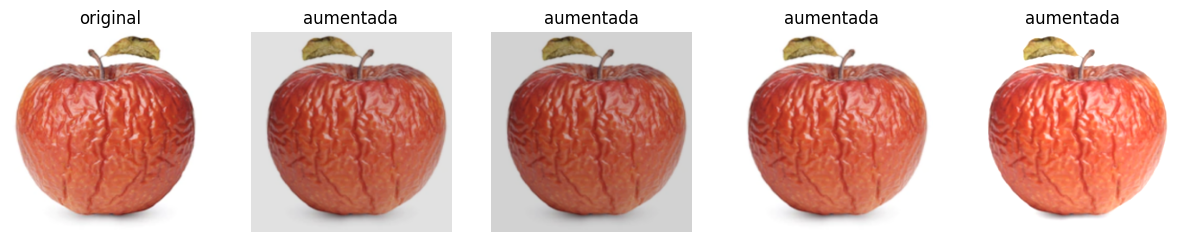

In [23]:
# Mira qué hace el aumento antes de entrenar (que las imágenes se vean razonables)
assert DESCARGAR_DATASET, "Activa DESCARGAR_DATASET = True, vuelve a ejecutar la sección 3 y la celda B1."
import matplotlib.pyplot as plt

p0 = sorted((Path(RUTA_DATOS) / "train" / CLASE_MALA).glob("*"))[0]
img0 = Image.open(p0).convert("RGB")
aug = transforms.Compose([transforms.Resize((TAM, TAM)),
                          transforms.RandomHorizontalFlip(p=0.5),
                          transforms.ColorJitter(brightness=0.3)])
fig, ejes = plt.subplots(1, 5, figsize=(15, 3))
ejes[0].imshow(img0.resize((TAM, TAM))); ejes[0].set_title("original")
for ax in ejes[1:]:
    ax.imshow(aug(img0)); ax.set_title("aumentada")
for ax in ejes:
    ax.axis("off")
plt.show()


In [24]:
h_exp = entrenar("exp1_aumento", tf_train_aug())

[exp1_aumento] clases=['freshapples', 'rottenapples'] | train=3431 (base 3431 + extra 0) val=604
[exp1_aumento] época 1/5 | loss=0.2408 | val F1=0.973 recall=0.960 precisión=0.985
[exp1_aumento] época 2/5 | loss=0.1155 | val F1=0.986 recall=0.986 precisión=0.986
[exp1_aumento] época 3/5 | loss=0.0936 | val F1=0.978 recall=0.972 precisión=0.986
[exp1_aumento] época 4/5 | loss=0.0859 | val F1=0.982 recall=0.997 precisión=0.967
[exp1_aumento] época 5/5 | loss=0.0870 | val F1=0.989 recall=0.994 precisión=0.983
Listo en 113s | modelo: exp1_aumento.pt | historial: exp1_aumento_val.json


### Comparación en validación (no en `test`)

In [25]:
def mejor_epoca(nombre):
    h = json.loads(Path(f"{REPO}/resultados/{nombre}_val.json").read_text())
    return max(h, key=lambda e: e["f1_mala"])

for nombre in [MODELO_NUEVO.stem, "exp1_aumento"]:
    try:
        b = mejor_epoca(nombre)
        print(f"{nombre:14s} | época {b['epoca']} | recall={b['recall_mala']:.3f} "
              f"precisión={b['precision_mala']:.3f} F1={b['f1_mala']:.3f}")
    except FileNotFoundError:
        print(f"{nombre}: aún no hay resultados.")
# ¿Subió el recall al menos 0,01 sin que la precisión caiga de forma importante? Entonces la hipótesis se apoya.
# Si no, se refuta, y eso también es un resultado válido que debes explicar.
# Con un val pequeño, diferencias de 0,01 pueden ser ruido: repite con otra semilla (SEMILLA = 43) y mira la tendencia.

baseline_v2    | época 5 | recall=0.997 precisión=0.986 F1=0.992
exp1_aumento   | época 5 | recall=0.994 precisión=0.983 F1=0.989


# Parte D. Más experimentos (requiere el dataset)



### D1. Experimento 5: sanas y deterioradas de 100×100 (necesita `manzanas.zip` en `/content`)

In [26]:
import re
EXTRA_ZIP, RUTA_EXTRA = "/content/manzanas.zip", "/content/extra_sanas"   # sube el zip nuevo con ese nombre
N_SANAS, N_MALAS = 120, 60
PATRON = re.compile(r"^(r\d*_)?(\d+)_(\d+)\.(jpg|jpeg|png)$", re.IGNORECASE)   # el segundo número (100-103) identifica el lote

!unzip -oq {EXTRA_ZIP} -d /content/extra_origen
shutil.rmtree(RUTA_EXTRA, ignore_errors=True)
for carpeta, clase, n in [("sanas", "freshapples", N_SANAS), ("malas", "rottenapples", N_MALAS)]:
    por_clave = {}
    for p in sorted(Path("/content/extra_origen").rglob(f"{carpeta}/*")):
        m = PATRON.match(p.name)
        if not m or Image.open(p).size != (100, 100):
            continue                         # fotos reales de otro tamaño: no se usan para entrenar
        k = (int(m.group(3)), int(m.group(2)))        # (lote, número de fotograma)
        if k not in por_clave or (por_clave[k].name.lower().startswith("r") and not m.group(1)):
            por_clave[k] = p                 # una por fotograma; se prefiere la original
    claves = sorted(por_clave)
    pos = sorted({round(i * (len(claves) - 1) / (n - 1)) for i in range(n)}) if n < len(claves) else range(len(claves))
    destino = Path(RUTA_EXTRA) / "train" / clase
    destino.mkdir(parents=True)
    for i in pos:
        shutil.copy(por_clave[claves[i]], destino / f"nuevas_{por_clave[claves[i]].name}")
    print(clase, len(claves), "->", len(list(destino.glob("*"))))

# control: ninguna imagen nueva puede ser idéntica a algo de val o test
h_ex = {hashlib.md5(p.read_bytes()).hexdigest() for p in Path(RUTA_EXTRA).rglob("*.jpg")}
print("duplicados con val/test:", len(h_ex & (set(hashes("val")) | set(hashes("test")))))

freshapples 574 -> 120
rottenapples 88 -> 60
duplicados con val/test: 0


In [27]:
h_exp5 = entrenar_si_falta("exp5_sanas_y_malas", tf_train(), extra_train=f"{RUTA_EXTRA}/train")

[exp5_sanas_y_malas] clases=['freshapples', 'rottenapples'] | train=3611 (base 3431 + extra 180) val=604
[exp5_sanas_y_malas] época 1/5 | loss=0.2462 | val F1=0.977 recall=0.969 precisión=0.986
[exp5_sanas_y_malas] época 2/5 | loss=0.1156 | val F1=0.982 recall=0.983 precisión=0.980
[exp5_sanas_y_malas] época 3/5 | loss=0.0965 | val F1=0.978 recall=0.969 precisión=0.988
[exp5_sanas_y_malas] época 4/5 | loss=0.0747 | val F1=0.984 recall=0.983 precisión=0.986
[exp5_sanas_y_malas] época 5/5 | loss=0.0704 | val F1=0.983 recall=0.997 precisión=0.970
Listo en 107s | modelo: exp5_sanas_y_malas.pt | historial: exp5_sanas_y_malas_val.json


### D2. Recortes con fondo blanco (lo que ve el clasificador en uso)



In [28]:
from torchvision.transforms.functional import to_tensor

RUTA_RECORTES = "/content/recortes"
RUTA_REC_EXT = "/content/recortes_ext"
EXTS = {".jpg", ".jpeg", ".png"}


@torch.no_grad()
def recorte_de_la_manzana(imgs):
    """Para cada imagen (una sola manzana) devuelve el recorte con fondo blanco, o None si el detector no la ve."""
    salidas = detector([to_tensor(i).to(dev) for i in imgs])
    recortes = []
    for img, out in zip(imgs, salidas):
        idx = torch.where(torch.isin(out["labels"], IDS_FRUTA) & (out["scores"] >= UMBRAL_RESCATE))[0]
        if len(idx) == 0:
            recortes.append(None)
            continue
        k = int(idx[out["scores"][idx].argmax()])             # la manzana con mayor puntaje
        mascara = (out["masks"][k, 0] > UMBRAL_MASCARA).cpu().numpy()
        if mascara.sum() < MIN_AREA_FRAC * img.width * img.height:
            recortes.append(None)
            continue
        recortes.append(recortar(np.asarray(img), out["boxes"][k].cpu().numpy(), mascara))
    return recortes


def generar_recortes(origen, destino, lote=8):
    """Convierte una carpeta ImageFolder en otra con los mismos recortes que produce el sistema.
    Las imágenes donde el detector no encuentra la manzana se omiten (y se cuentan).
    Si ya existe una carpeta hecha con otras clases de COCO, se regenera."""
    origen, destino = Path(origen), Path(destino)
    marca = destino / "_listo.json"
    if marca.exists():
        info = json.loads(marca.read_text())
        if info.get("clases") == CLASES_FRUTA:
            print("Ya existe:", destino)
            return info["resumen"]
        print(f"Los recortes de {destino} se hicieron con otras clases de COCO: se regeneran.")
        shutil.rmtree(destino)
    resumen = {}
    for carpeta in sorted(p for p in origen.iterdir() if p.is_dir()):
        archivos = sorted(p for p in carpeta.rglob("*") if p.suffix.lower() in EXTS)
        (destino / carpeta.name).mkdir(parents=True, exist_ok=True)
        ok = 0
        for i in range(0, len(archivos), lote):
            grupo = archivos[i:i + lote]
            imgs = []
            for p in grupo:
                im = Image.open(p).convert("RGB")
                if max(im.size) > MAX_LADO:
                    im.thumbnail((MAX_LADO, MAX_LADO))
                imgs.append(im)
            for p, rec in zip(grupo, recorte_de_la_manzana(imgs)):
                if rec is not None:
                    rec.save(destino / carpeta.name / f"{p.stem}.png")
                    ok += 1
        resumen[carpeta.name] = {"imagenes": len(archivos), "recortadas": ok, "sin_deteccion": len(archivos) - ok}
        print(f"  {origen.name}/{carpeta.name}: {ok}/{len(archivos)} recortadas")
    marca.write_text(json.dumps({"clases": CLASES_FRUTA, "resumen": resumen}, indent=2))
    return resumen

  train/freshapples: 1387/1440 recortadas
  train/rottenapples: 1804/1991 recortadas
  val/freshapples: 244/253 recortadas
  val/rottenapples: 323/351 recortadas
{
  "train": {
    "freshapples": {
      "imagenes": 1440,
      "recortadas": 1387,
      "sin_deteccion": 53
    },
    "rottenapples": {
      "imagenes": 1991,
      "recortadas": 1804,
      "sin_deteccion": 187
    }
  },
  "val": {
    "freshapples": {
      "imagenes": 253,
      "recortadas": 244,
      "sin_deteccion": 9
    },
    "rottenapples": {
      "imagenes": 351,
      "recortadas": 323,
      "sin_deteccion": 28
    }
  }
}


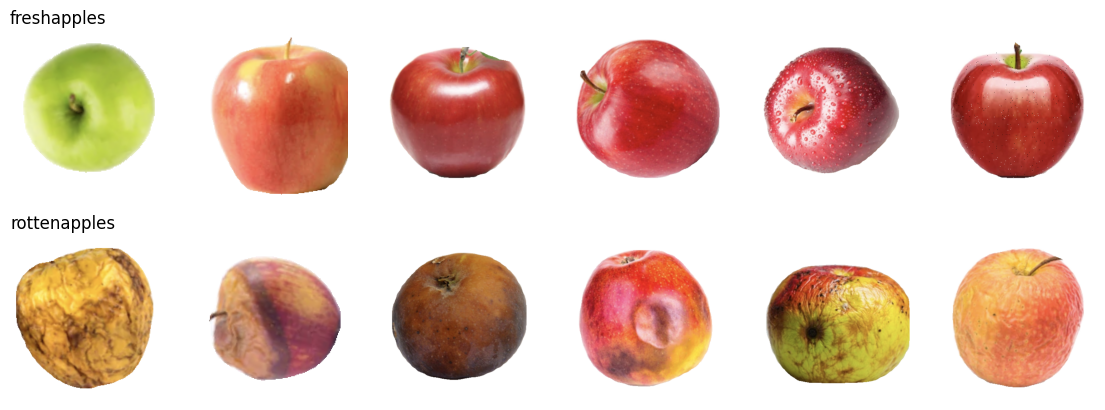

In [29]:
assert DESCARGAR_DATASET, "Activa DESCARGAR_DATASET = True y ejecuta B1 y B2."
res_recortes = {s: generar_recortes(f"{RUTA_DATOS}/{s}", f"{RUTA_RECORTES}/{s}") for s in ["train", "val"]}
print(json.dumps(res_recortes, indent=2))
# Mira cuántas se perdieron en cada clase. Si pierdes muchas deterioradas, el conjunto de recortes queda sesgado:
# anótalo en la bitácora, porque esas son justo las que el sistema tampoco verá como manzana.

# Ver unos cuantos recortes antes de entrenar (¿se ven como los del sistema?)
import matplotlib.pyplot as plt
fig, ejes = plt.subplots(2, 6, figsize=(14, 5))
for fila, clase in enumerate(["freshapples", "rottenapples"]):
    archivos = sorted((Path(RUTA_RECORTES) / "train" / clase).glob("*.png"))
    for ax, f in zip(ejes[fila], random.Random(1).sample(archivos, min(6, len(archivos)))):
        ax.imshow(Image.open(f)); ax.axis("off")
    ejes[fila][0].set_title(clase, loc="left")
plt.show()

In [30]:
import collections
COCO = pesos_det.meta["categories"]
UMBRAL_DIAG = 0.35
sin = [p for p in sorted(Path(f"{RUTA_DATOS}/val/rottenapples").glob("*"))
       if not (Path(RUTA_RECORTES) / "val" / "rottenapples" / f"{p.stem}.png").exists()]
conteo, sin_nada = collections.Counter(), 0
with torch.no_grad():
    for i in range(0, len(sin), 8):
        imgs = []
        for p in sin[i:i + 8]:
            im = Image.open(p).convert("RGB")
            if max(im.size) > MAX_LADO:
                im.thumbnail((MAX_LADO, MAX_LADO))
            imgs.append(im)
        for out in detector([to_tensor(im).to(dev) for im in imgs]):
            ok = out["scores"] >= UMBRAL_DIAG
            if not ok.any():
                sin_nada += 1
            else:
                mejor = out["scores"][ok].argmax()
                conteo[COCO[int(out["labels"][ok][mejor])]] += 1
print(f"{len(sin)} deterioradas de val sin recorte")
print(f"  el detector no ve nada con puntaje >= {UMBRAL_DIAG}: {sin_nada}")
print("  lo que ve en su lugar (clase de COCO):", conteo.most_common(8))

28 deterioradas de val sin recorte
  el detector no ve nada con puntaje >= 0.35: 2
  lo que ve en su lugar (clase de COCO): [('bowl', 17), ('banana', 2), ('vase', 2), ('apple', 1), ('donut', 1), ('pizza', 1), ('umbrella', 1), ('bird', 1)]


### D3. Evaluar cualquier modelo sobre una carpeta de recortes (y referencia `baseline_v2`)

In [31]:
def evaluar_en(ruta, nombre):
    ck = torch.load(f"{REPO}/modelos/{nombre}.pt", map_location=dev)
    m = crear_modelo(len(ck["clases"]), congelar=False)
    m.load_state_dict(ck["state_dict"])
    m = m.to(dev).eval()
    ds = datasets.ImageFolder(str(ruta), tf_eval())
    assert ds.classes == ck["clases"], (ds.classes, ck["clases"])
    dl = torch.utils.data.DataLoader(ds, batch_size=32, num_workers=2)
    return evaluar_loader(m, dl, ck["clases"])


# Referencia: baseline_v2 (entrenado con fotos completas) sobre los recortes de val
r = evaluar_en(f"{RUTA_RECORTES}/val", "baseline_v2")
print(f"baseline_v2 en val-recortes | recall={r['recall_mala']:.3f} precisión={r['precision_mala']:.3f} "
      f"F1={r['f1_mala']:.3f} | {r['matriz_confusion']} | n={r['n']}")

baseline_v2 en val-recortes | recall=0.994 precisión=0.976 F1=0.985 | {'TP': 321, 'FP': 8, 'FN': 2, 'TN': 236} | n=567


### D4. Experimento 6: entrenar con recortes (cambia solo el preprocesamiento)

In [32]:
h_exp6 = entrenar_si_falta("exp6_recortes", tf_train(), ruta_datos=RUTA_RECORTES)

[exp6_recortes] clases=['freshapples', 'rottenapples'] | train=3191 (base 3191 + extra 0) val=567
[exp6_recortes] época 1/5 | loss=0.2200 | val F1=0.972 recall=0.985 precisión=0.961
[exp6_recortes] época 2/5 | loss=0.1164 | val F1=0.980 recall=0.978 precisión=0.981
[exp6_recortes] época 3/5 | loss=0.0867 | val F1=0.983 recall=0.985 precisión=0.981
[exp6_recortes] época 4/5 | loss=0.0749 | val F1=0.981 recall=0.985 precisión=0.978
[exp6_recortes] época 5/5 | loss=0.0742 | val F1=0.978 recall=0.963 precisión=0.994
Listo en 105s | modelo: exp6_recortes.pt | historial: exp6_recortes_val.json


### D5. Experimento 7: recortes + aumento de color (lo único que cambia)

In [33]:
def tf_train_color():
    return transforms.Compose([
        transforms.Resize((TAM, TAM)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ColorJitter(brightness=0.3, contrast=0.2, saturation=0.4, hue=0.03),   # el matiz casi no se toca
        transforms.ToTensor(),
        transforms.Normalize(MEDIA, STD),
    ])

h_exp7 = entrenar_si_falta("exp7_recortes_color", tf_train_color(), ruta_datos=RUTA_RECORTES)

[exp7_recortes_color] clases=['freshapples', 'rottenapples'] | train=3191 (base 3191 + extra 0) val=567
[exp7_recortes_color] época 1/5 | loss=0.2464 | val F1=0.980 recall=0.985 precisión=0.975
[exp7_recortes_color] época 2/5 | loss=0.1364 | val F1=0.981 recall=0.981 precisión=0.981
[exp7_recortes_color] época 3/5 | loss=0.1028 | val F1=0.983 recall=0.981 precisión=0.984
[exp7_recortes_color] época 4/5 | loss=0.1010 | val F1=0.984 recall=0.981 precisión=0.988
[exp7_recortes_color] época 5/5 | loss=0.0878 | val F1=0.976 recall=0.960 precisión=0.994
Listo en 159s | modelo: exp7_recortes_color.pt | historial: exp7_recortes_color_val.json


### D6. Fotos de otra fuente (Defectos_Manzanas) y su recorte



In [34]:
assert DESCARGAR_DATASET, "Activa DESCARGAR_DATASET = True y ejecuta B1 y B2."
import io, re, collections, urllib.request

NDJSON = Path("/content/defectosmanzanas.ndjson")
EXT = Path("/content/ext_manzanas")
FRAC_TEST_EXT = 0.30
ID_GOOD, ID_PODRIDO = 3, 6

if not NDJSON.exists():
    from google.colab import files
    print("Sube el archivo defectosmanzanas.ndjson")
    subida_nd = files.upload()
    assert subida_nd, "No se subió el archivo."
    shutil.move(list(subida_nd)[0], NDJSON)

filas = [json.loads(l) for l in NDJSON.read_text(encoding="utf-8").splitlines() if l.strip()]
nombres_cls = filas[0]["class_names"]
assert nombres_cls[str(ID_GOOD)] == "good" and nombres_cls[str(ID_PODRIDO)] == "podrido", nombres_cls


def base_foto(archivo):
    return re.sub(r"_jpg\.rf\..*", "", archivo)       # quita el sufijo de Roboflow: copias de una misma foto


def etiqueta(r):
    ids = {int(s[0]) for s in (r.get("annotations") or {}).get("segments", [])}
    if ids == {ID_GOOD}:
        return "freshapples"
    if ID_PODRIDO in ids and ID_GOOD not in ids:
        return "rottenapples"
    return None


grupos = collections.defaultdict(list)
for r in filas[1:]:
    grupos[base_foto(r["file"])].append(r)

elegidas, en_conflicto = {}, 0
for b, rs in grupos.items():
    et = {etiqueta(r) for r in rs} - {None}
    if len(et) > 1:
        en_conflicto += 1
    elif len(et) == 1:
        c = et.pop()
        elegidas[b] = (c, next(r for r in rs if etiqueta(r) == c))
print(f"Fotos originales: {len(grupos)} | usables: {len(elegidas)} | en conflicto: {en_conflicto}")
print(" ", collections.Counter(c for c, _ in elegidas.values()))

crudas = EXT / "crudas"
crudas.mkdir(parents=True, exist_ok=True)
descargadas, fallidas = {}, 0
for b, (c, r) in elegidas.items():
    ruta = crudas / (re.sub(r"[^\w.-]", "_", "ext_" + b) + ".jpg")
    if not ruta.exists():
        try:
            with urllib.request.urlopen(r["url"], timeout=30) as resp:
                Image.open(io.BytesIO(resp.read())).convert("RGB").save(ruta, quality=95)
        except Exception:
            fallidas += 1
            continue
    descargadas[b] = (c, ruta)
print(f"Descargadas: {len(descargadas)} | fallidas: {fallidas}")


def md5(ruta):
    return hashlib.md5(Path(ruta).read_bytes()).hexdigest()


propios = {md5(p) for p in Path(RUTA_DATOS).rglob("*") if p.suffix.lower() in EXTS}
repetidas = [b for b, (_, ruta) in descargadas.items() if md5(ruta) in propios]
for b in repetidas:
    descargadas.pop(b)
print(f"Idénticas a tu dataset (descartadas): {len(repetidas)}")

for parte in ["train", "test"]:
    shutil.rmtree(EXT / parte, ignore_errors=True)
rng = random.Random(SEMILLA)
resumen_ext = {}
for clase in ["freshapples", "rottenapples"]:
    bs = sorted(b for b, (c, _) in descargadas.items() if c == clase)
    rng.shuffle(bs)
    n_te = round(len(bs) * FRAC_TEST_EXT)
    for i, b in enumerate(bs):
        parte = "test" if i < n_te else "train"
        destino = EXT / parte / clase
        destino.mkdir(parents=True, exist_ok=True)
        shutil.copy(descargadas[b][1], destino / descargadas[b][1].name)
    resumen_ext[clase] = {"train": len(bs) - n_te, "test": n_te}
print("Reparto:", json.dumps(resumen_ext, indent=2))

# Recortes de esas fotos (ext_train se suma al entrenamiento; ext_test NO se entrena nunca)
res_rec_ext = {s: generar_recortes(EXT / s, f"{RUTA_REC_EXT}/{s}") for s in ["train", "test"]}
print(json.dumps(res_rec_ext, indent=2))
# Estas fotos pueden traer más de una manzana: se toma la de mayor puntaje. Mira unas cuantas antes de entrenar.

Sube el archivo defectosmanzanas.ndjson


Saving defectosmanzanas.ndjson to defectosmanzanas.ndjson
Fotos originales: 531 | usables: 185 | en conflicto: 2
  Counter({'freshapples': 101, 'rottenapples': 84})
Descargadas: 185 | fallidas: 0
Idénticas a tu dataset (descartadas): 0
Reparto: {
  "freshapples": {
    "train": 71,
    "test": 30
  },
  "rottenapples": {
    "train": 59,
    "test": 25
  }
}
  train/freshapples: 70/71 recortadas
  train/rottenapples: 57/59 recortadas
  test/freshapples: 29/30 recortadas
  test/rottenapples: 25/25 recortadas
{
  "train": {
    "freshapples": {
      "imagenes": 71,
      "recortadas": 70,
      "sin_deteccion": 1
    },
    "rottenapples": {
      "imagenes": 59,
      "recortadas": 57,
      "sin_deteccion": 2
    }
  },
  "test": {
    "freshapples": {
      "imagenes": 30,
      "recortadas": 29,
      "sin_deteccion": 1
    },
    "rottenapples": {
      "imagenes": 25,
      "recortadas": 25,
      "sin_deteccion": 0
    }
  }
}


### D7. Experimento 8: exp7 + fotos de otra fuente

In [35]:
h_exp8 = entrenar_si_falta("exp8_recortes_color_ext", tf_train_color(), ruta_datos=RUTA_RECORTES,
                           extra_train=f"{RUTA_REC_EXT}/train")

[exp8_recortes_color_ext] clases=['freshapples', 'rottenapples'] | train=3318 (base 3191 + extra 127) val=567
[exp8_recortes_color_ext] época 1/5 | loss=0.2411 | val F1=0.972 recall=0.966 precisión=0.978
[exp8_recortes_color_ext] época 2/5 | loss=0.1330 | val F1=0.978 recall=0.969 precisión=0.987
[exp8_recortes_color_ext] época 3/5 | loss=0.1213 | val F1=0.980 recall=0.972 precisión=0.987
[exp8_recortes_color_ext] época 4/5 | loss=0.0941 | val F1=0.985 recall=0.985 precisión=0.985
[exp8_recortes_color_ext] época 5/5 | loss=0.0968 | val F1=0.985 recall=0.988 precisión=0.982
Listo en 164s | modelo: exp8_recortes_color_ext.pt | historial: exp8_recortes_color_ext_val.json


### D8. Comparar todos los modelos en `val` y en `ext_test` (recortes)



In [96]:
MODELOS6 = ["baseline_v2", "exp5_sanas_y_malas", "exp6_recortes", "exp7_recortes_color",
            "exp8_recortes_color_ext", "exp9_recortes_color_ext_rojas"]
CONJUNTOS = {"val-recortes": f"{RUTA_RECORTES}/val", "ext_test-recortes": f"{RUTA_REC_EXT}/test"}
for conj, ruta in CONJUNTOS.items():
    if not Path(ruta).exists():
        continue
    print(f"\n{conj}")
    for nombre in MODELOS6:
        if not Path(f"{REPO}/modelos/{nombre}.pt").exists():
            print(f"  {nombre:26s} (aún no entrenado)")
            continue
        r = evaluar_en(ruta, nombre)
        c = r["matriz_confusion"]
        print(f"  {nombre:26s} recall={r['recall_mala']:.3f} precisión={r['precision_mala']:.3f} "
              f"F1={r['f1_mala']:.3f} exactitud={r['accuracy']:.3f} | FP={c['FP']} FN={c['FN']} | n={r['n']}")
# ext_test es pequeño (unas 55 fotos): una o dos imágenes mueven mucho las métricas. Cuenta FP y FN, no solo porcentajes.


val-recortes
  baseline_v2                recall=0.994 precisión=0.976 F1=0.985 exactitud=0.982 | FP=8 FN=2 | n=567
  exp5_sanas_y_malas         recall=0.981 precisión=0.978 F1=0.980 exactitud=0.977 | FP=7 FN=6 | n=567
  exp6_recortes              recall=0.985 precisión=0.981 F1=0.983 exactitud=0.981 | FP=6 FN=5 | n=567
  exp7_recortes_color        recall=0.981 precisión=0.988 F1=0.984 exactitud=0.982 | FP=4 FN=6 | n=567
  exp8_recortes_color_ext    recall=0.988 precisión=0.982 F1=0.985 exactitud=0.982 | FP=6 FN=4 | n=567
  exp9_recortes_color_ext_rojas recall=0.985 precisión=0.981 F1=0.983 exactitud=0.981 | FP=6 FN=5 | n=567

ext_test-recortes
  baseline_v2                recall=0.960 precisión=0.571 F1=0.716 exactitud=0.648 | FP=18 FN=1 | n=54
  exp5_sanas_y_malas         recall=1.000 precisión=0.658 F1=0.794 exactitud=0.759 | FP=13 FN=0 | n=54
  exp6_recortes              recall=0.960 precisión=0.727 F1=0.828 exactitud=0.815 | FP=9 FN=1 | n=54
  exp7_recortes_color        recall=1.

### D9. Repetir con otras semillas (43 y 44)



In [37]:
CONFIGS = {   # nombre -> (transformación, extra_train)
    "exp6_recortes": (tf_train(), None),
    "exp7_recortes_color": (tf_train_color(), None),
    "exp8_recortes_color_ext": (tf_train_color(), f"{RUTA_REC_EXT}/train"),
}
SEMILLAS = [43, 44]
for nombre, (tf, extra) in CONFIGS.items():
    for s in SEMILLAS:
        if Path(f"{REPO}/modelos/{nombre}_s{s}.pt").exists():
            continue
        entrenar(f"{nombre}_s{s}", tf, ruta_datos=RUTA_RECORTES, extra_train=extra, semilla=s)

import statistics as st
print("\nSemillas 42 (la original), 43 y 44:")
for conj, ruta in CONJUNTOS.items():
    if not Path(ruta).exists():
        continue
    print(f"\n{conj}")
    for nombre in CONFIGS:
        rs = [evaluar_en(ruta, n) for n in [nombre] + [f"{nombre}_s{s}" for s in SEMILLAS]
              if Path(f"{REPO}/modelos/{n}.pt").exists()]
        rec = [r["recall_mala"] for r in rs]
        fp = [r["matriz_confusion"]["FP"] for r in rs]
        print(f"  {nombre:26s} recall: media {st.mean(rec):.3f} (mín {min(rec):.3f}, máx {max(rec):.3f}) | "
              f"falsos positivos: {fp}")

[exp6_recortes_s43] clases=['freshapples', 'rottenapples'] | train=3191 (base 3191 + extra 0) val=567
[exp6_recortes_s43] época 1/5 | loss=0.2648 | val F1=0.972 recall=0.981 precisión=0.964
[exp6_recortes_s43] época 2/5 | loss=0.1176 | val F1=0.978 recall=0.975 precisión=0.981
[exp6_recortes_s43] época 3/5 | loss=0.0943 | val F1=0.976 recall=0.963 precisión=0.990
[exp6_recortes_s43] época 4/5 | loss=0.0797 | val F1=0.983 recall=0.981 precisión=0.984
[exp6_recortes_s43] época 5/5 | loss=0.0860 | val F1=0.984 recall=0.978 precisión=0.991
Listo en 106s | modelo: exp6_recortes_s43.pt | historial: exp6_recortes_s43_val.json
[exp6_recortes_s44] clases=['freshapples', 'rottenapples'] | train=3191 (base 3191 + extra 0) val=567
[exp6_recortes_s44] época 1/5 | loss=0.2375 | val F1=0.972 recall=0.963 precisión=0.981
[exp6_recortes_s44] época 2/5 | loss=0.1058 | val F1=0.977 recall=0.969 precisión=0.984
[exp6_recortes_s44] época 3/5 | loss=0.0856 | val F1=0.986 recall=0.988 precisión=0.985
[exp6_r

### D10. Comparar los modelos con tus fotos reales



In [97]:
for s in (43, 44):
    entrenar_si_falta(f"exp9_recortes_color_ext_rojas_s{s}", tf_train_color(),
                      ruta_datos=RUTA_RECORTES, extra_train=str(COMB), semilla=s)
for s in (43, 44):
    r = evaluar_en(f"{RUTA_REC_EXT}/test", f"exp9_recortes_color_ext_rojas_s{s}")
    c = r["matriz_confusion"]
    print(s, f"recall={r['recall_mala']:.3f} precisión={r['precision_mala']:.3f} FP={c['FP']} FN={c['FN']}")

[exp9_recortes_color_ext_rojas_s43] clases=['freshapples', 'rottenapples'] | train=3498 (base 3191 + extra 307) val=567
[exp9_recortes_color_ext_rojas_s43] época 1/5 | loss=0.2716 | val F1=0.967 recall=0.957 precisión=0.978
[exp9_recortes_color_ext_rojas_s43] época 2/5 | loss=0.1393 | val F1=0.978 recall=0.981 precisión=0.975
[exp9_recortes_color_ext_rojas_s43] época 3/5 | loss=0.1214 | val F1=0.972 recall=0.957 precisión=0.987
[exp9_recortes_color_ext_rojas_s43] época 4/5 | loss=0.1106 | val F1=0.975 recall=0.963 precisión=0.987
[exp9_recortes_color_ext_rojas_s43] época 5/5 | loss=0.0998 | val F1=0.985 recall=0.985 precisión=0.985
Listo en 169s | modelo: exp9_recortes_color_ext_rojas_s43.pt | historial: exp9_recortes_color_ext_rojas_s43_val.json
[exp9_recortes_color_ext_rojas_s44] clases=['freshapples', 'rottenapples'] | train=3498 (base 3191 + extra 307) val=567
[exp9_recortes_color_ext_rojas_s44] época 1/5 | loss=0.2708 | val F1=0.975 recall=0.972 precisión=0.978
[exp9_recortes_colo

In [43]:
!mkdir -p /content/fotos_prueba/sanas /content/fotos_prueba/malas

In [100]:
import shutil
from google.colab import files

!mkdir -p /content/guardar
!cp -r {REPO}/modelos {REPO}/resultados {REPO}/docs /content/guardar/
!cp -r /content/comparaciones /content/guardar/ 2>/dev/null
shutil.make_archive("/content/proyecto_resultados", "zip", "/content/guardar")
files.download("/content/proyecto_resultados.zip")

cp: cannot stat '/content/proyectoAprendizaje/docs': No such file or directory


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
import pandas as pd

def cargar_clasificador(nombre):
    """Cambia el clasificador que usa analizar(). El detector no cambia."""
    global clasificador, clases_clf
    ck = torch.load(f"{REPO}/modelos/{nombre}.pt", map_location=dev)
    clases_clf = ck["clases"]
    clasificador = crear_modelo(len(clases_clf), congelar=False)
    clasificador.load_state_dict(ck["state_dict"])
    clasificador = clasificador.to(dev).eval()

CARPETAS = {"sanas": "/content/fotos_prueba/sanas", "malas": "/content/fotos_prueba/malas"}
MODELOS_FOTOS = ["baseline_v2", "exp5_sanas_y_malas", "exp8_recortes_color_ext",
                 "exp9_recortes_color_ext_rojas"]
print("Modelos a comparar:", MODELOS_FOTOS)

filas = []
for nombre in MODELOS_FOTOS:
    cargar_clasificador(nombre)
    for tipo, carpeta in CARPETAS.items():
        for ruta in sorted(Path(carpeta).glob("*")):
            if ruta.suffix.lower() not in EXTS:
                continue
            res = analizar(Image.open(ruta))
            filas.append({"modelo": nombre, "tipo": tipo, "foto": ruta.name,
                          "manzanas": res["total"], "deterioradas": res["deterioradas"]})

df = pd.DataFrame(filas)
if df.empty:
    print("No hay fotos en", list(CARPETAS.values()))
else:
    r = df.groupby(["modelo", "tipo"])[["manzanas", "deterioradas"]].sum()
    r["% deteriorada"] = (100 * r["deterioradas"] / r["manzanas"]).round(1)
    display(r)
    display(df.pivot_table(index=["tipo", "foto"], columns="modelo", values="deterioradas", aggfunc="sum"))

cargar_clasificador("baseline_v2")      # deja cargado el modelo de referencia
print("Clasificador restaurado: baseline_v2")

Modelos a comparar: ['baseline_v2', 'exp5_sanas_y_malas', 'exp8_recortes_color_ext', 'exp9_recortes_color_ext_rojas']


manzanas  deterioradas  % deteriorada
modelo                        tipo                                        
baseline_v2                   malas         8             7           87.5
                              sanas        45            20           44.4
exp5_sanas_y_malas            malas         8             7           87.5
                              sanas        45            19           42.2
exp8_recortes_color_ext       malas         8             7           87.5
                              sanas        45            24           53.3
exp9_recortes_color_ext_rojas malas         8             7           87.5
                              sanas        45            17           37.8

modelo                                   baseline_v2  exp5_sanas_y_malas  \
tipo  foto                                                                 
malas images (11).jpg                              4                   4   
      images (12).jpg                              2                   2   
      istockphoto-147058486-612x612.jpg            1                   1   
sanas good-apple.jpeg                             14                  15   
      images (10).jpg                              0                   0   
      images (7).jpg                               1                   1   
      images (8).jpg                               2                   1   
      images (9).jpg                               1                   0   
      manzana-fuji-lista.jpg                       2                   2   

modelo                                   exp8_recortes_color_ext  \
tipo  foto                                                         
malas images (11).jpg                                          4   
      images (12).jpg                                          2   
      istockphoto-147058486-612x612.jpg                        1   
sanas good-apple.jpeg                                         20   
      images (10).jpg                                          0   
      images (7).jpg                                           1   
      images (8).jpg                                           2   
      images (9).jpg                                           0   
      manzana-fuji-lista.jpg                                   1   

modelo                                   exp9_recortes_color_ext_rojas  
tipo  foto                                                              
malas images (11).jpg                                                4  
      images (12).jpg                                                2  
      istockphoto-147058486-612x612.jpg                              1  
sanas good-apple.jpeg                                               15  
      images (10).jpg                                                0  
      images (7).jpg                                                 1  
      images (8).jpg                                                 0  
      images (9).jpg                                                 0  
      manzana-fuji-lista.jpg                                         1

Clasificador restaurado: baseline_v2


In [46]:
df["det/total"] = df["deterioradas"].astype(str) + "/" + df["manzanas"].astype(str)
display(df.pivot_table(index=["tipo", "foto"], columns="modelo",
                       values="det/total", aggfunc="first"))

modelo                                  baseline_v2 exp5_sanas_y_malas  \
tipo  foto                                                               
malas images (11).jpg                           4/5                4/5   
      images (12).jpg                           2/2                2/2   
      istockphoto-147058486-612x612.jpg         1/1                1/1   
sanas good-apple.jpeg                         14/29              15/29   
      images (10).jpg                           0/3                0/3   
      images (7).jpg                            1/3                1/3   
      images (8).jpg                            2/2                1/2   
      images (9).jpg                            1/3                0/3   
      manzana-fuji-lista.jpg                    2/5                2/5   

modelo                                  exp8_recortes_color_ext  \
tipo  foto                                                        
malas images (11).jpg                                       4/5   
      images (12).jpg                                       2/2   
      istockphoto-147058486-612x612.jpg                     1/1   
sanas good-apple.jpeg                                     20/29   
      images (10).jpg                                       0/3   
      images (7).jpg                                        1/3   
      images (8).jpg                                        2/2   
      images (9).jpg                                        0/3   
      manzana-fuji-lista.jpg                                1/5   

modelo                                  exp9_recortes_color_ext_rojas  
tipo  foto                                                             
malas images (11).jpg                                             4/5  
      images (12).jpg                                             2/2  
      istockphoto-147058486-612x612.jpg                           1/1  
sanas good-apple.jpeg                                           15/29  
      images (10).jpg                                             0/3  
      images (7).jpg                                              1/3  
      images (8).jpg                                              0/2  
      images (9).jpg                                              0/3  
      manzana-fuji-lista.jpg                                      1/5

In [47]:
cargar_clasificador("exp9_recortes_color_ext_rojas")
res = analizar(Image.open("/content/fotos_prueba/sanas/good-apple.jpeg"))
for d in res["instancias"]:
    print(d["id"], d["estado"], f"{d['prob_deteriorada']:.0%}")
cargar_clasificador("baseline_v2")

1 deteriorada 87%
2 sana 1%
3 sana 11%
4 deteriorada 63%
5 deteriorada 88%
6 sana 5%
7 sana 44%
8 deteriorada 96%
9 deteriorada 58%
10 sana 5%
11 sana 8%
12 deteriorada 95%
13 sana 4%
14 sana 16%
15 sana 13%
16 deteriorada 80%
17 deteriorada 83%
18 deteriorada 64%
19 deteriorada 51%
20 deteriorada 85%
21 sana 38%
22 sana 42%
23 deteriorada 64%
24 sana 6%
25 sana 14%
26 deteriorada 96%
27 deteriorada 84%
28 deteriorada 94%
29 sana 46%


In [48]:
cargar_clasificador("exp9_recortes_color_ext_rojas")
img = Image.open("/content/fotos_prueba/sanas/good-apple.jpeg")
res = analizar(img)
dibujar(res)          # si no muestra la imagen: display(dibujar(res))
cargar_clasificador("baseline_v2")

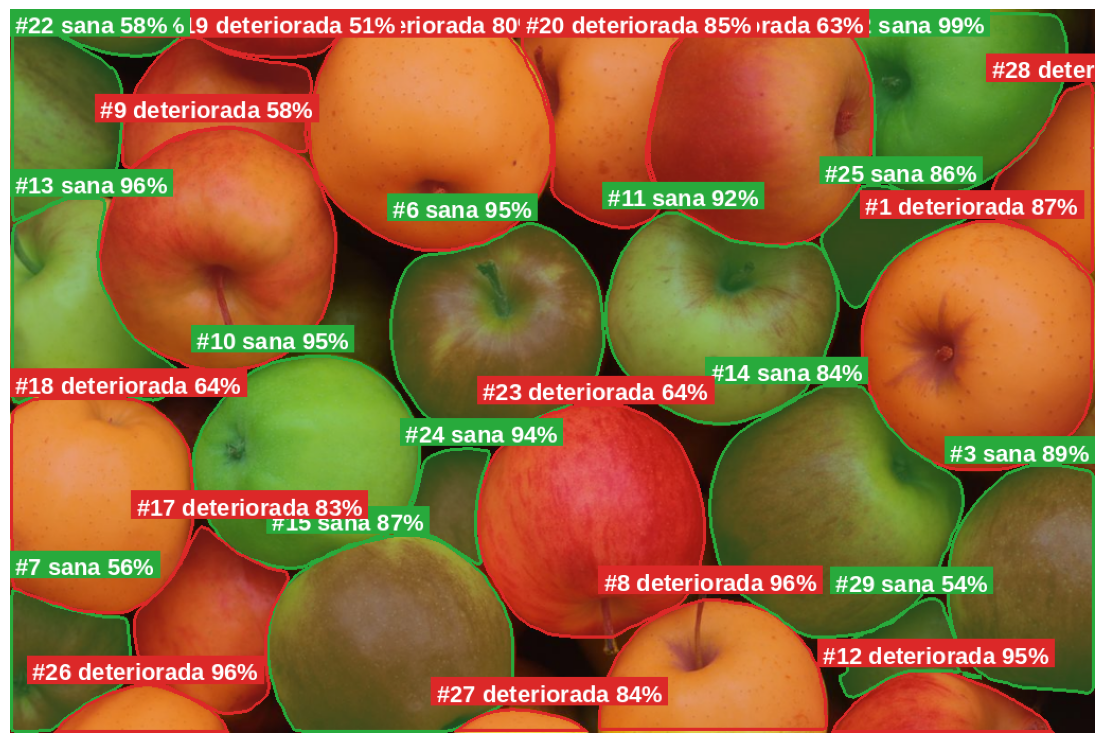

In [49]:
cargar_clasificador("exp9_recortes_color_ext_rojas")
img = Image.open("/content/fotos_prueba/sanas/good-apple.jpeg")
res = analizar(img)
out = dibujar(res)
out.save("/content/good_apple_exp9.png")
cargar_clasificador("baseline_v2")

import matplotlib.pyplot as plt
plt.figure(figsize=(14, 10)); plt.imshow(out); plt.axis("off"); plt.show()

In [45]:
# Foto con estados mezclados: qué dice cada modelo de cada manzana
RUTA_FOTO = "/content/images (6).jpg"      # pon aquí la ruta de la foto
img = Image.open(RUTA_FOTO)
for nombre in MODELOS_FOTOS:
    cargar_clasificador(nombre)
    res = analizar(img)
    print(f"\n{nombre}: {res['sanas']} sanas / {res['deterioradas']} deterioradas")
    for d in res["instancias"]:
        print(f"  #{d['id']}: {d['estado']:12s} P(deteriorada) = {d['prob_deteriorada']:.0%}")
cargar_clasificador("baseline_v2")


baseline_v2: 0 sanas / 3 deterioradas
  #1: deteriorada  P(deteriorada) = 100%
  #2: deteriorada  P(deteriorada) = 67%
  #3: deteriorada  P(deteriorada) = 100%

exp5_sanas_y_malas: 1 sanas / 2 deterioradas
  #1: deteriorada  P(deteriorada) = 100%
  #2: sana         P(deteriorada) = 41%
  #3: deteriorada  P(deteriorada) = 100%

exp8_recortes_color_ext: 0 sanas / 3 deterioradas
  #1: deteriorada  P(deteriorada) = 100%
  #2: deteriorada  P(deteriorada) = 75%
  #3: deteriorada  P(deteriorada) = 100%

exp9_recortes_color_ext_rojas: 1 sanas / 2 deterioradas
  #1: deteriorada  P(deteriorada) = 100%
  #2: sana         P(deteriorada) = 36%
  #3: deteriorada  P(deteriorada) = 100%


EXP 9

In [41]:
import shutil
from pathlib import Path

COMB = Path("/content/extra_comb/train")
for origen in [Path(RUTA_REC_EXT)/"train", Path(RUTA_EXTRA)/"train"]:
    for clase in ["freshapples", "rottenapples"]:
        destino = COMB/clase
        destino.mkdir(parents=True, exist_ok=True)
        for f in (origen/clase).glob("*"):
            shutil.copy(f, destino/f"{origen.parent.name}_{f.name}")

h_exp9 = entrenar_si_falta("exp9_recortes_color_ext_rojas", tf_train_color(),
                           ruta_datos=RUTA_RECORTES, extra_train=str(COMB))

[exp9_recortes_color_ext_rojas] clases=['freshapples', 'rottenapples'] | train=3498 (base 3191 + extra 307) val=567
[exp9_recortes_color_ext_rojas] época 1/5 | loss=0.2825 | val F1=0.970 recall=0.963 precisión=0.978
[exp9_recortes_color_ext_rojas] época 2/5 | loss=0.1562 | val F1=0.972 recall=0.960 precisión=0.984
[exp9_recortes_color_ext_rojas] época 3/5 | loss=0.1248 | val F1=0.972 recall=0.957 precisión=0.987
[exp9_recortes_color_ext_rojas] época 4/5 | loss=0.1106 | val F1=0.973 recall=0.957 precisión=0.990
[exp9_recortes_color_ext_rojas] época 5/5 | loss=0.1083 | val F1=0.983 recall=0.985 precisión=0.981
Listo en 172s | modelo: exp9_recortes_color_ext_rojas.pt | historial: exp9_recortes_color_ext_rojas_val.json
